### Imports

In [1]:
import pandas as pd
import  utils.utils_ipynb as uipy

EXCLUDE_GENERATORS = []

### Breast Cancer

In [2]:
breast_cancer_name = 'breast_cancer'
breast_cancer_num, breast_cancer_cat, breast_cancer_label = uipy.get_dataset_columns_name(breast_cancer_name)
breast_cancer_col_names = breast_cancer_num + breast_cancer_cat + [breast_cancer_label]

breast_cancer_fidelity_df = uipy.get_all_fidelity_results('./results', breast_cancer_name, EXCLUDE_GENERATORS)
breast_cancer_fidelity_expanded_df = uipy.get_expanded_fidelity_df(breast_cancer_fidelity_df, breast_cancer_col_names)

breast_cancer_utility_df = uipy.get_all_utility_results('./results', breast_cancer_name, EXCLUDE_GENERATORS)
breast_cancer_utility_expanded_df = uipy.get_expanded_utility_df(breast_cancer_utility_df)

breast_cancer_privacy_df = uipy.get_all_privacy_results('./results', breast_cancer_name, EXCLUDE_GENERATORS)
breast_cancer_privacy_expanded_df = uipy.get_expanded_privacy_df(breast_cancer_privacy_df)

breast_cancer_privacy_scores = uipy.get_all_mia_scores_results('./results', breast_cancer_name, EXCLUDE_GENERATORS)
breast_cancer_privacy_scores_expanded = uipy.get_expanded_mia_scores_df(breast_cancer_privacy_scores)

/home/alant/Home/TCC2/utils/utils_ipynb.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["generator"] = generator


#### Fidelidade - Gráficos

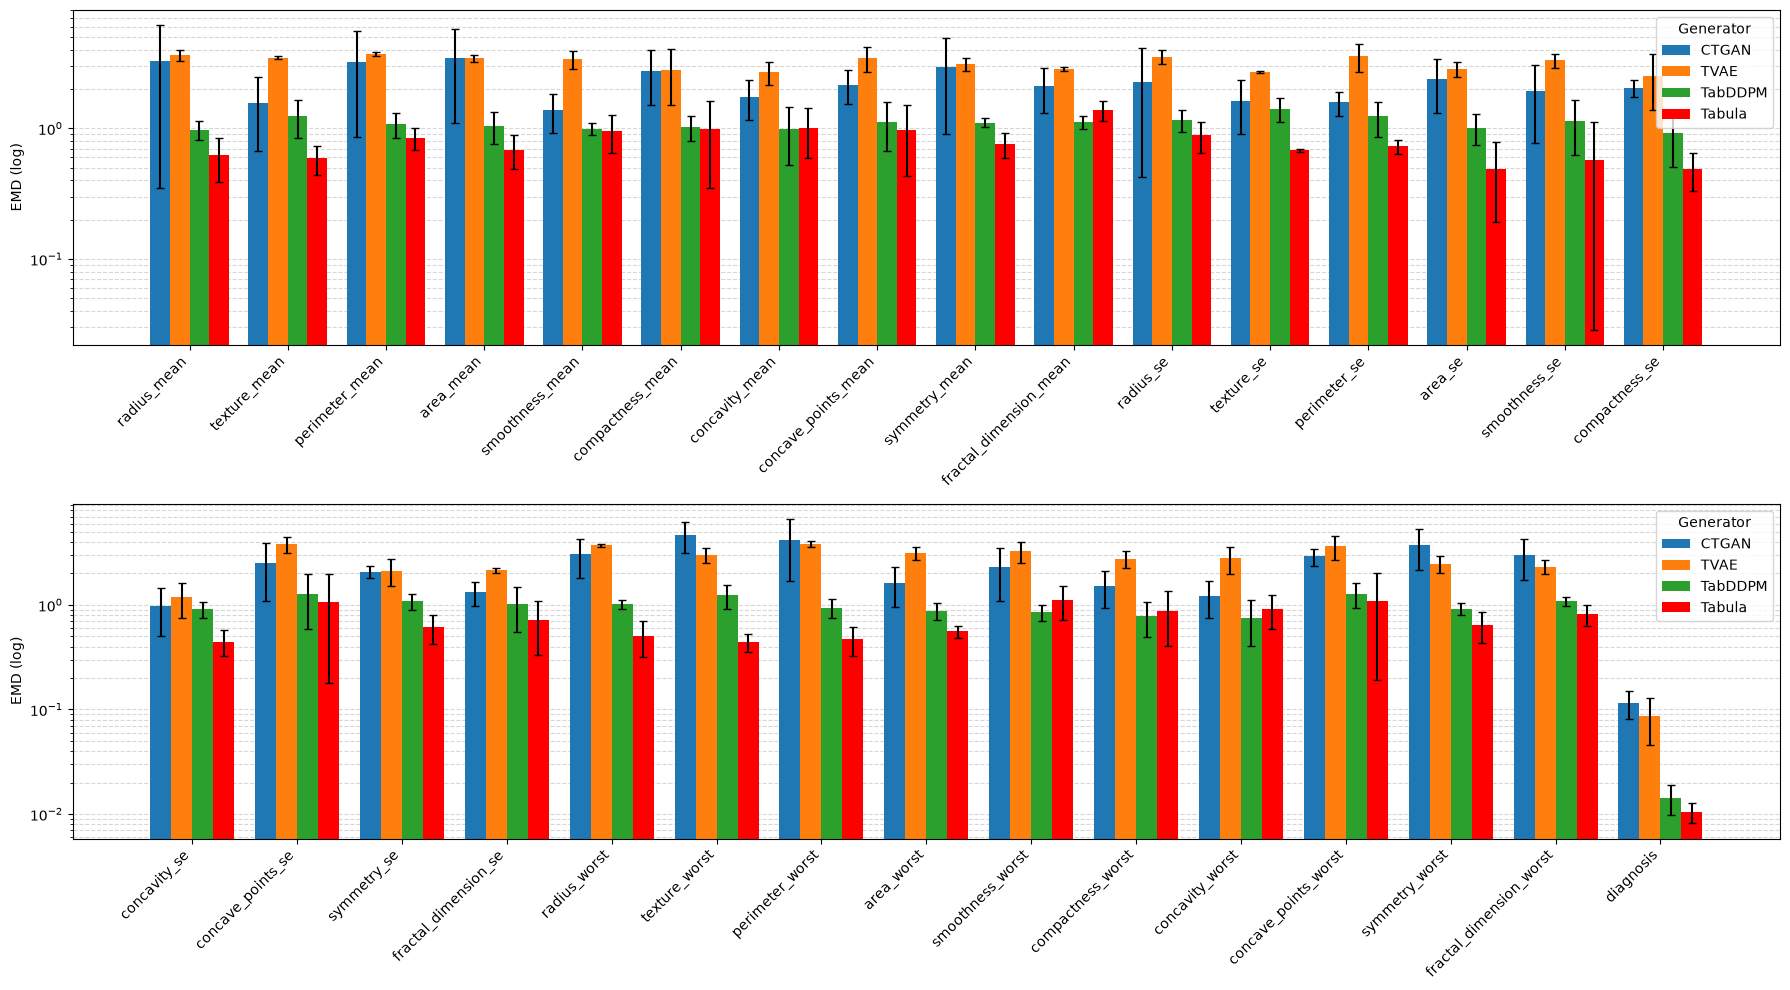

In [3]:
uipy.plot_fidelity_per_column(breast_cancer_fidelity_expanded_df, 'EMD', breast_cancer_col_names, breast_cancer_name, n_parts=2, with_caption=False)

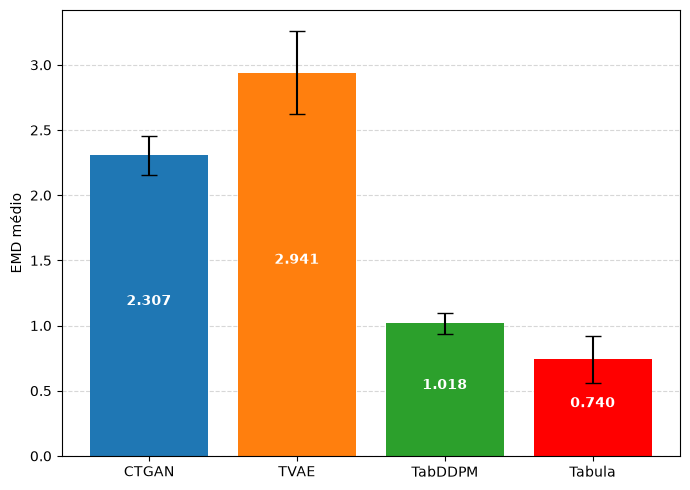

In [4]:
uipy.plot_fidelity_mean(breast_cancer_fidelity_expanded_df, 'EMD', breast_cancer_name, with_caption=False)

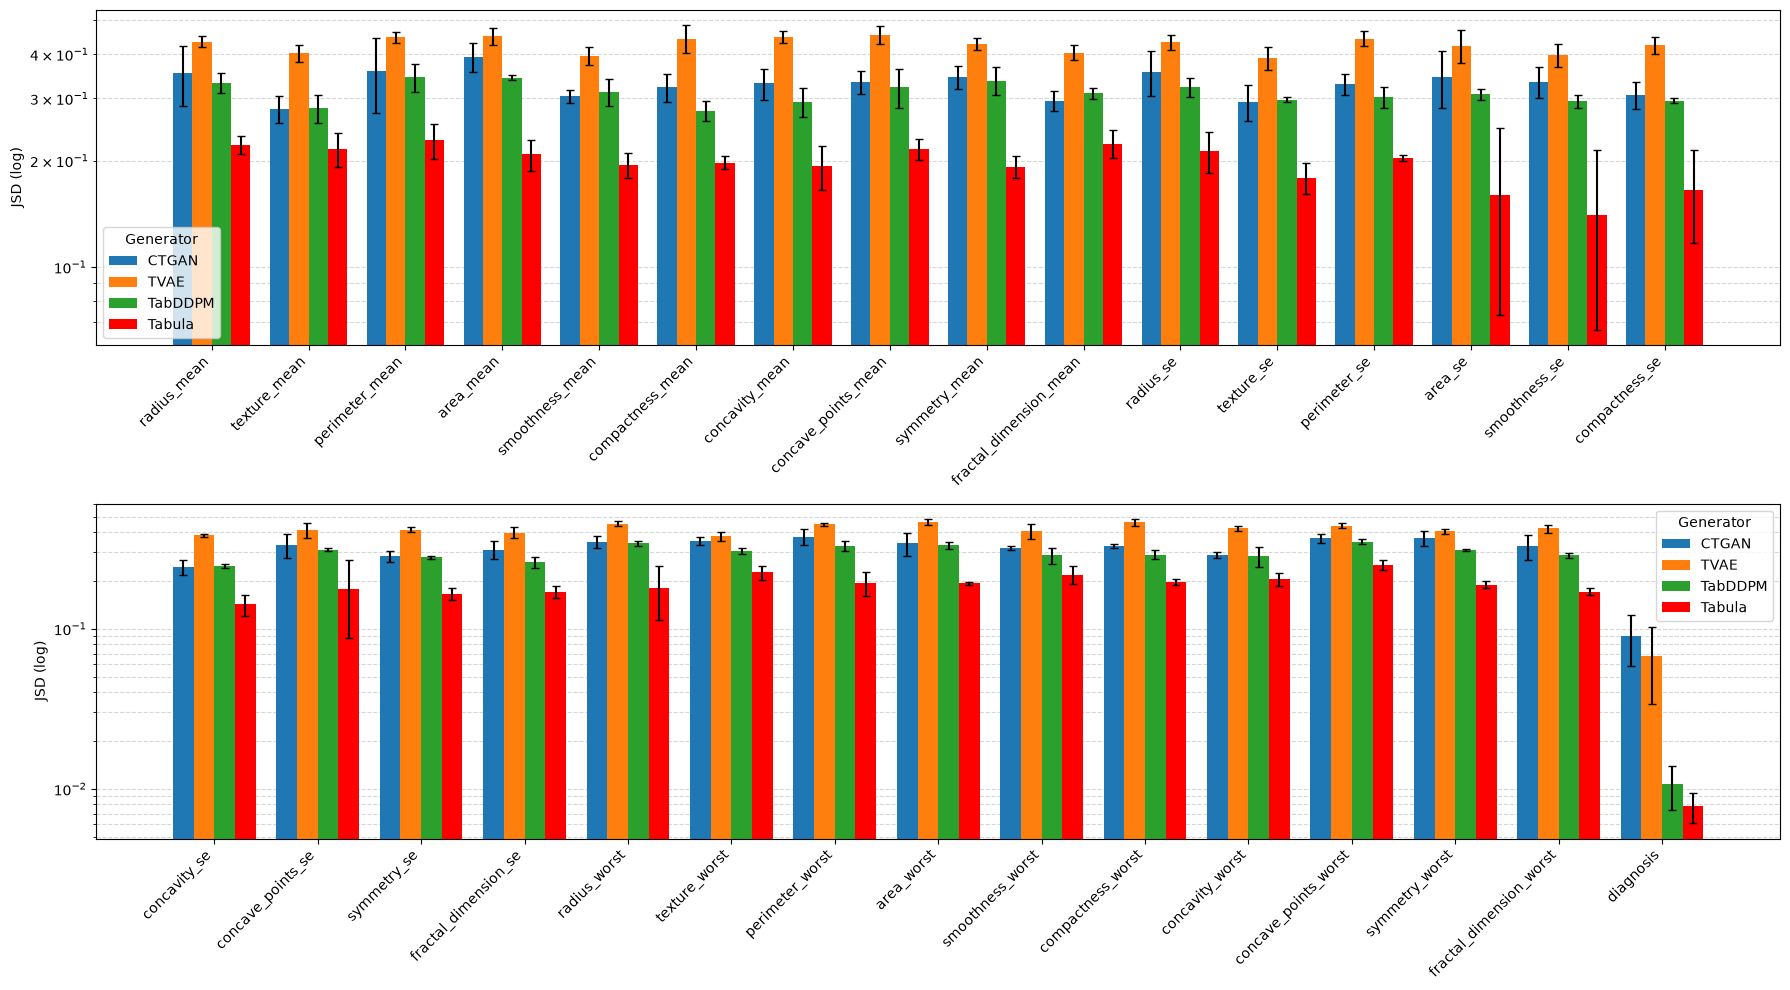

In [5]:
uipy.plot_fidelity_per_column(breast_cancer_fidelity_expanded_df, 'JSD', breast_cancer_col_names, breast_cancer_name, n_parts=2, with_caption=False)

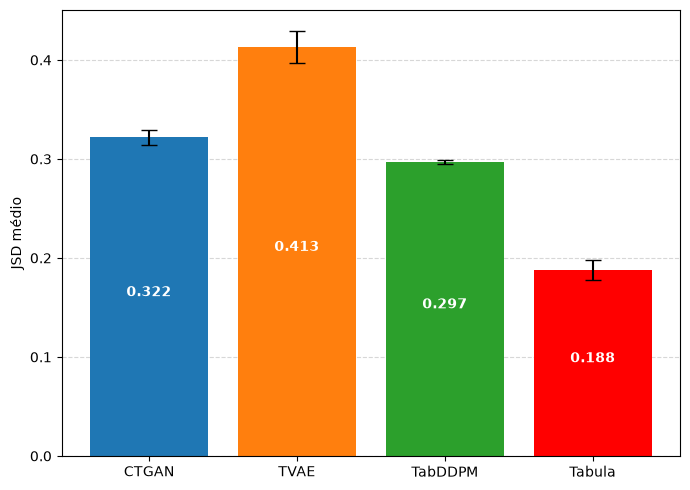

In [6]:
uipy.plot_fidelity_mean(breast_cancer_fidelity_expanded_df, 'JSD', breast_cancer_name, with_caption=False)

#### Fidelidade - Tabela

In [7]:
uipy.get_fidelity_table(breast_cancer_fidelity_expanded_df)

,EMD,JSD
Gerador,,
CTGAN,2.307 ± 0.149,0.322 ± 0.007
TVAE,2.941 ± 0.317,0.413 ± 0.016
TabDDPM,1.018 ± 0.082,0.297 ± 0.002
Tabula,0.740 ± 0.181,0.188 ± 0.010


#### Utilidade - Gráficos

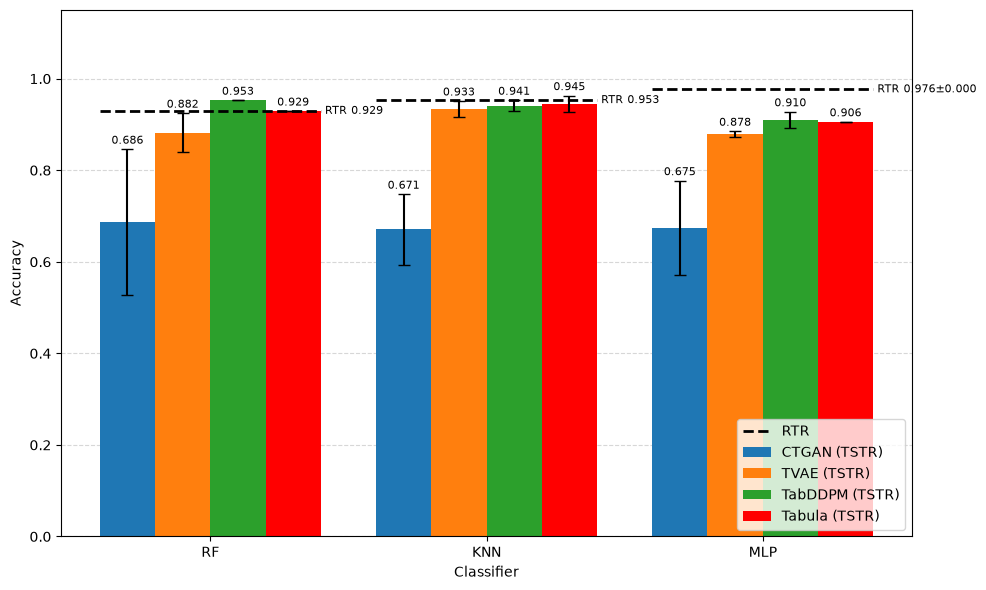

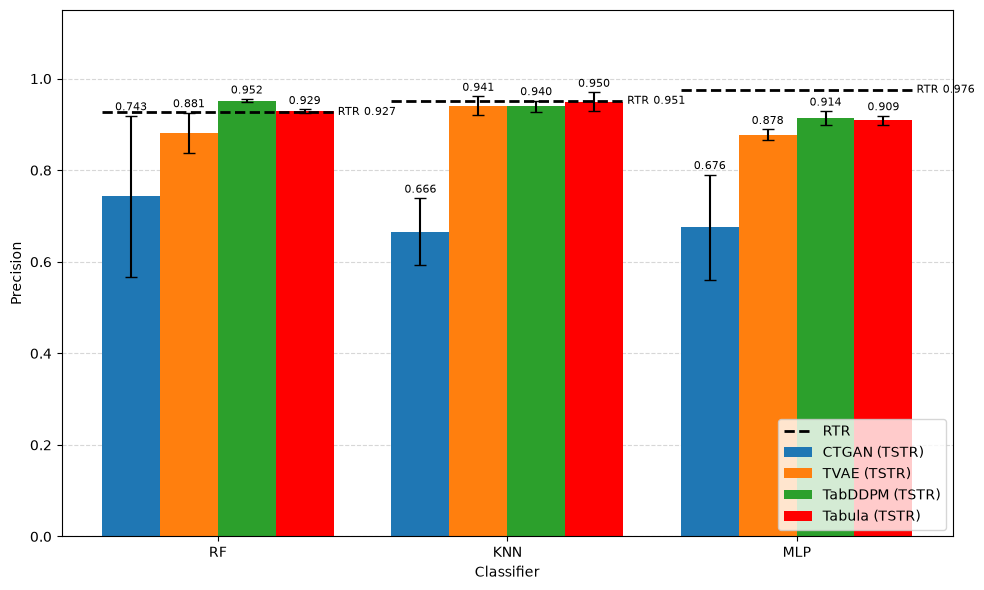

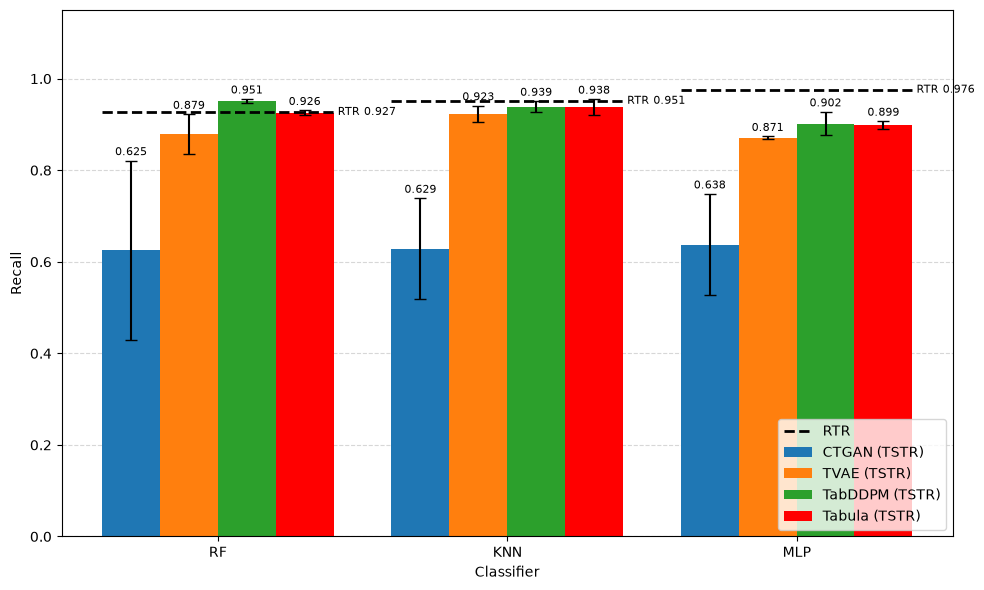

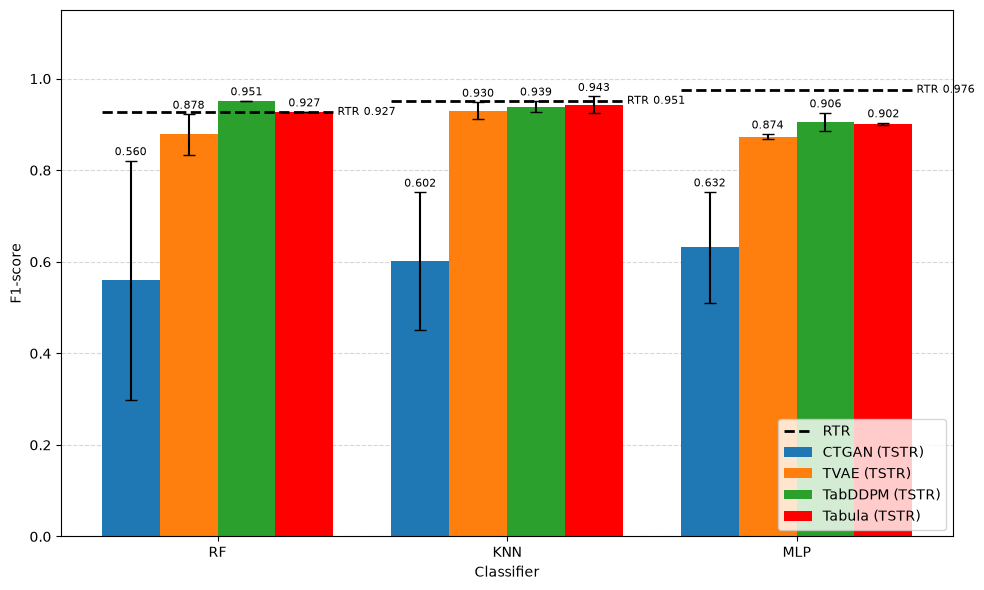

In [8]:
UTILITY_METRICS = ['accuracy', 'precision', 'recall', 'f1_score']

for metric in UTILITY_METRICS:
    uipy.plot_utility(breast_cancer_utility_expanded_df, metric, breast_cancer_name)


In [9]:
uipy.get_utility_table(breast_cancer_utility_expanded_df, metric='f1_score')

,RF,KNN,MLP
Modelo,,,
Baseline (RTR),0.927 ± 0.000,0.951 ± 0.000,0.976 ± 0.000
CTGAN,0.560 ± 0.261,0.602 ± 0.150,0.632 ± 0.121
TVAE,0.878 ± 0.044,0.930 ± 0.019,0.874 ± 0.006
TabDDPM,0.951 ± 0.000,0.939 ± 0.012,0.906 ± 0.020
Tabula,0.927 ± 0.001,0.943 ± 0.019,0.902 ± 0.002


#### Privacidade - Gráficos

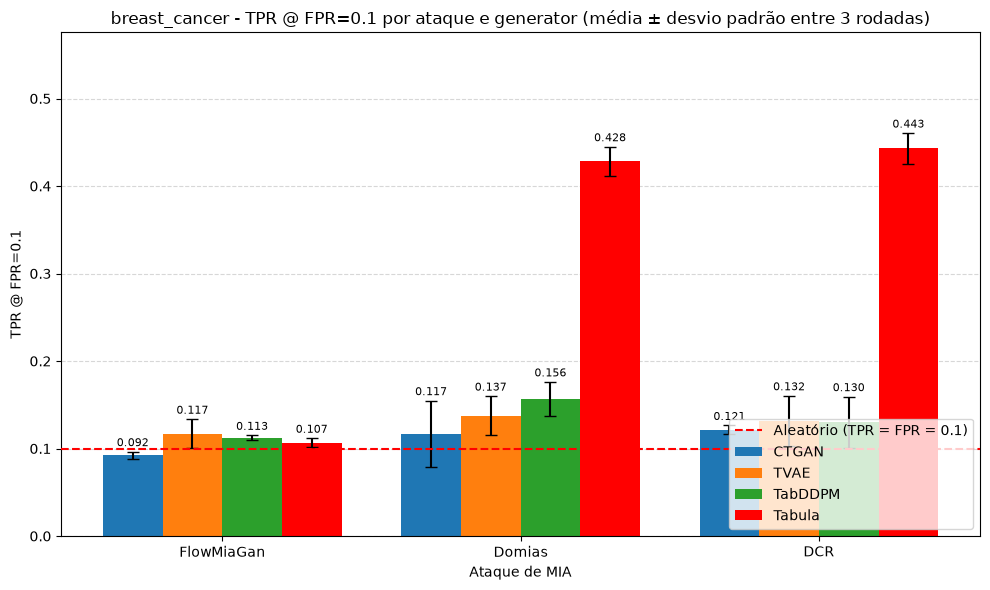

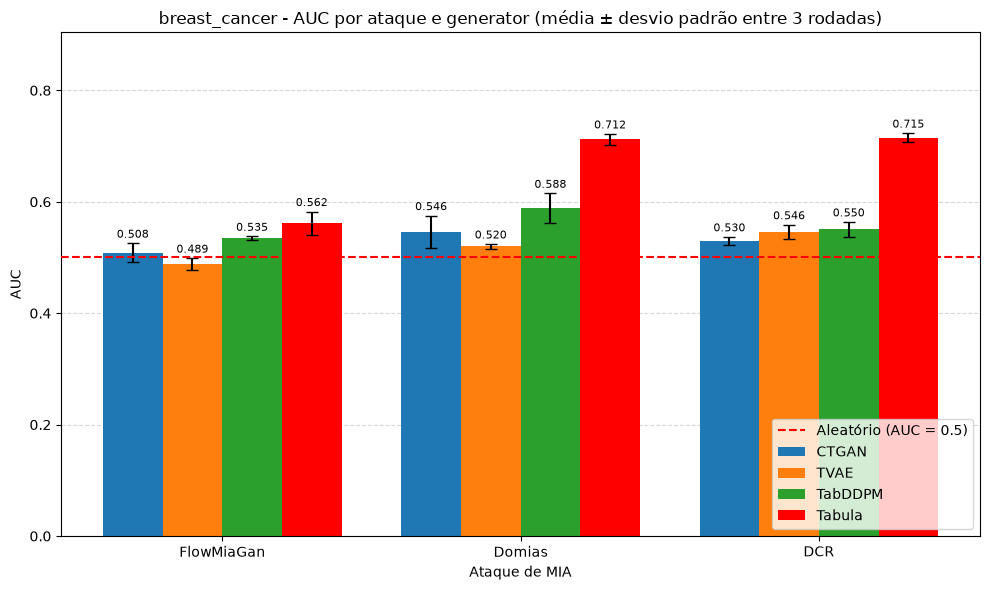

In [10]:
PRIVACY_METRICS = ['tpr@fpr', 'auc']

for metric in PRIVACY_METRICS:
    uipy.plot_privacy(breast_cancer_privacy_expanded_df, metric, breast_cancer_name)


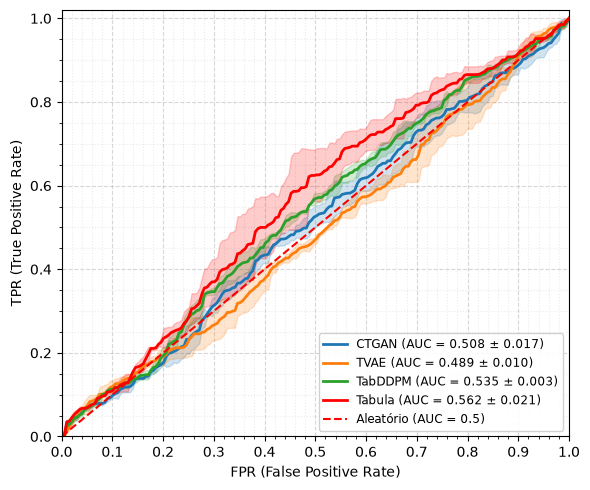

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [11]:
uipy.plot_mia_roc_curve(breast_cancer_privacy_scores_expanded, breast_cancer_name, attacks=['FlowMiaGan'], separate_plots=True)

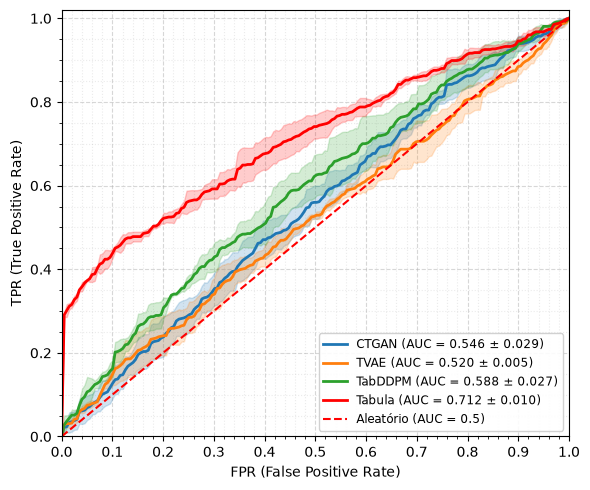

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [12]:
uipy.plot_mia_roc_curve(breast_cancer_privacy_scores_expanded, breast_cancer_name, attacks=['Domias'], separate_plots=True)

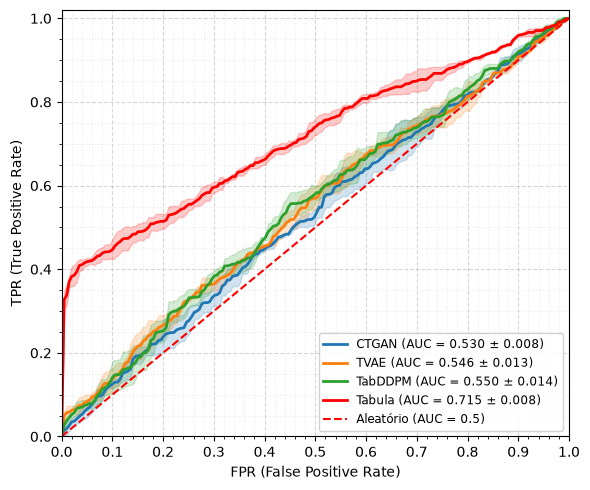

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [13]:
uipy.plot_mia_roc_curve(breast_cancer_privacy_scores_expanded, breast_cancer_name, attacks=['DCR'], separate_plots=True)

#### Privacidade - Tabela

In [14]:
uipy.get_privacy_table(breast_cancer_privacy_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.508 ± 0.017  0.092 ± 0.004  0.546 ± 0.029  0.117 ± 0.038   
TVAE     0.489 ± 0.010  0.117 ± 0.017  0.520 ± 0.005  0.137 ± 0.023   
TabDDPM  0.535 ± 0.003  0.113 ± 0.003  0.588 ± 0.027  0.156 ± 0.020   
Tabula   0.562 ± 0.021  0.107 ± 0.005  0.712 ± 0.010  0.428 ± 0.017   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.530 ± 0.008  0.121 ± 0.005  
TVAE     0.546 ± 0.013  0.132 ± 0.029  
TabDDPM  0.550 ± 0.014  0.130 ± 0.029  
Tabula   0.715 ± 0.008  0.443 ± 0.018

### Cidds

In [15]:
cidds_name = 'cidds'
cidds_num, cidds_cat, cidds_label = uipy.get_dataset_columns_name(cidds_name)
cidds_col_names = cidds_num + cidds_cat + [cidds_label]

cidds_fidelity_df = uipy.get_all_fidelity_results('./results', cidds_name, EXCLUDE_GENERATORS)
cidds_fidelity_expanded_df = uipy.get_expanded_fidelity_df(cidds_fidelity_df, cidds_col_names)

cidds_utility_df = uipy.get_all_utility_results('./results', cidds_name, EXCLUDE_GENERATORS)
cidds_utility_expanded_df = uipy.get_expanded_utility_df(cidds_utility_df)

cidds_privacy_df = uipy.get_all_privacy_results('./results', cidds_name, EXCLUDE_GENERATORS)
cidds_privacy_expanded_df = uipy.get_expanded_privacy_df(cidds_privacy_df)

cidds_privacy_scores = uipy.get_all_mia_scores_results('./results', cidds_name, EXCLUDE_GENERATORS)
cidds_privacy_scores_expanded = uipy.get_expanded_mia_scores_df(cidds_privacy_scores)

#### Fidelidade - Gráficos

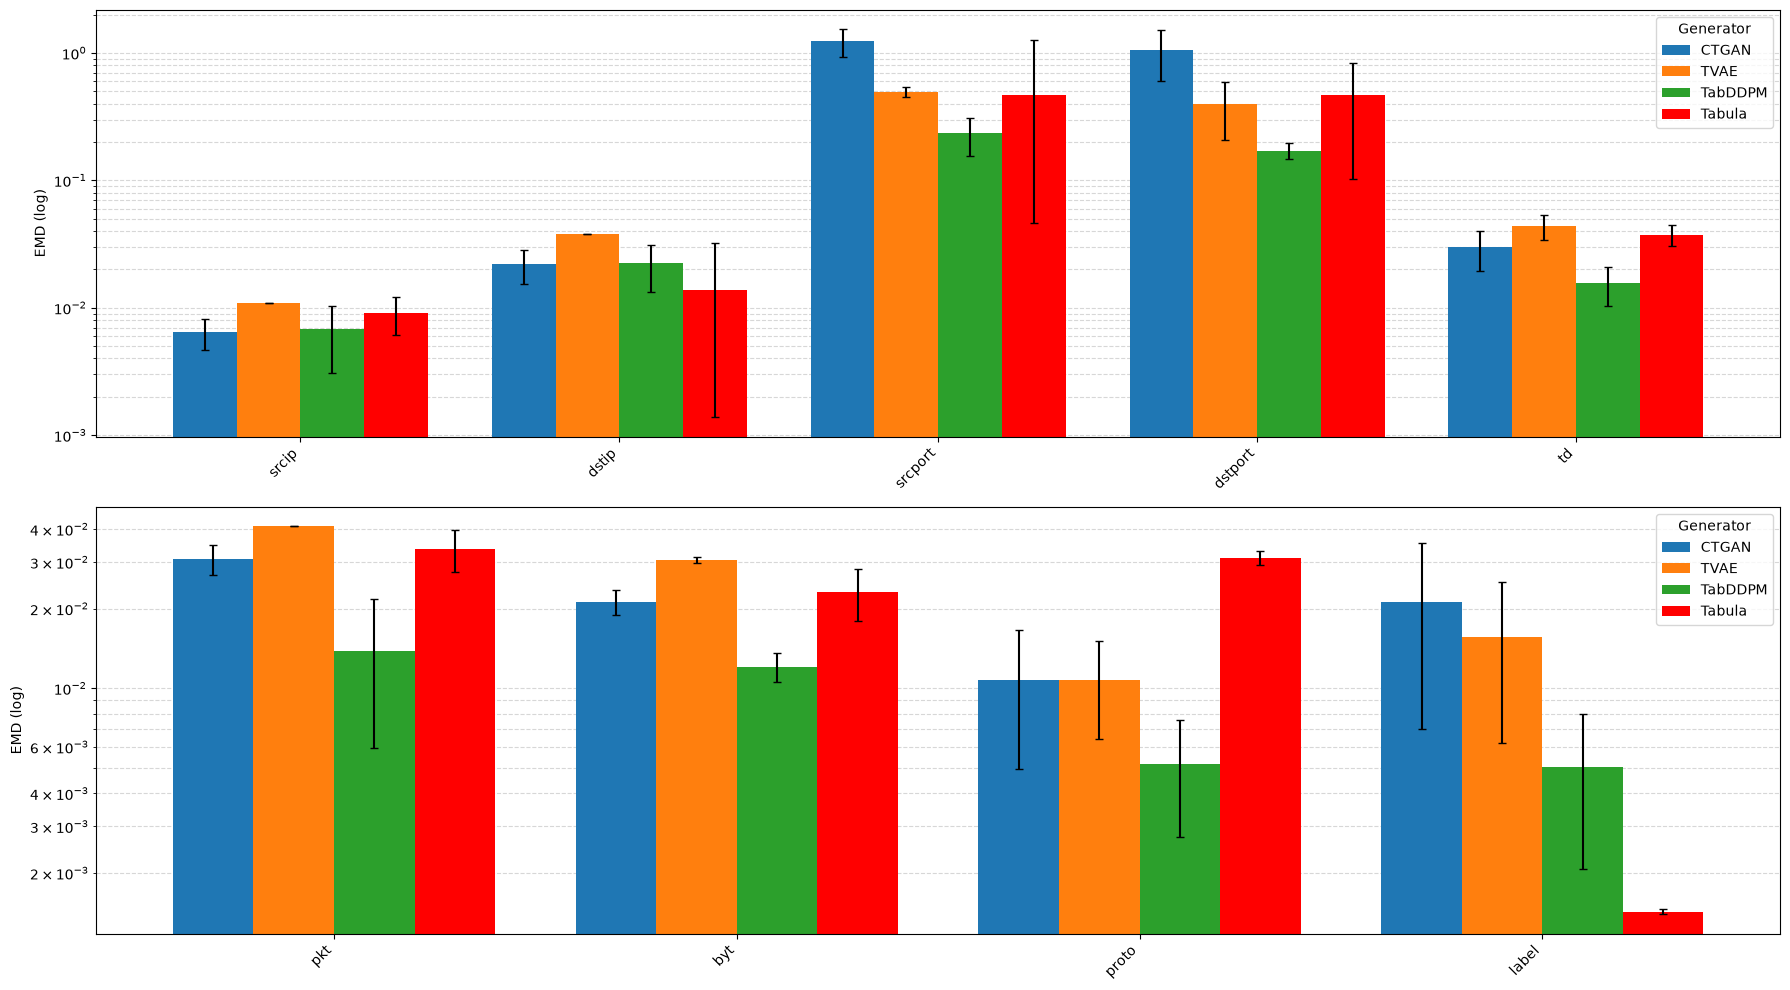

In [16]:
uipy.plot_fidelity_per_column(cidds_fidelity_expanded_df, 'EMD', cidds_col_names, cidds_name, n_parts=2, with_caption=False)

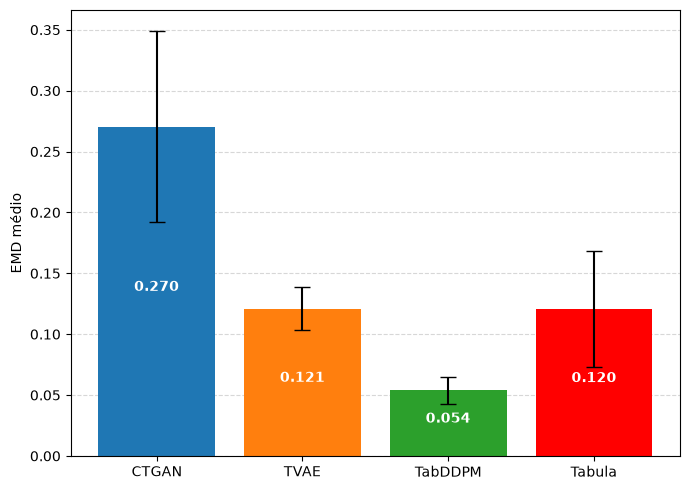

In [17]:
uipy.plot_fidelity_mean(cidds_fidelity_expanded_df, 'EMD', cidds_name, with_caption=False)

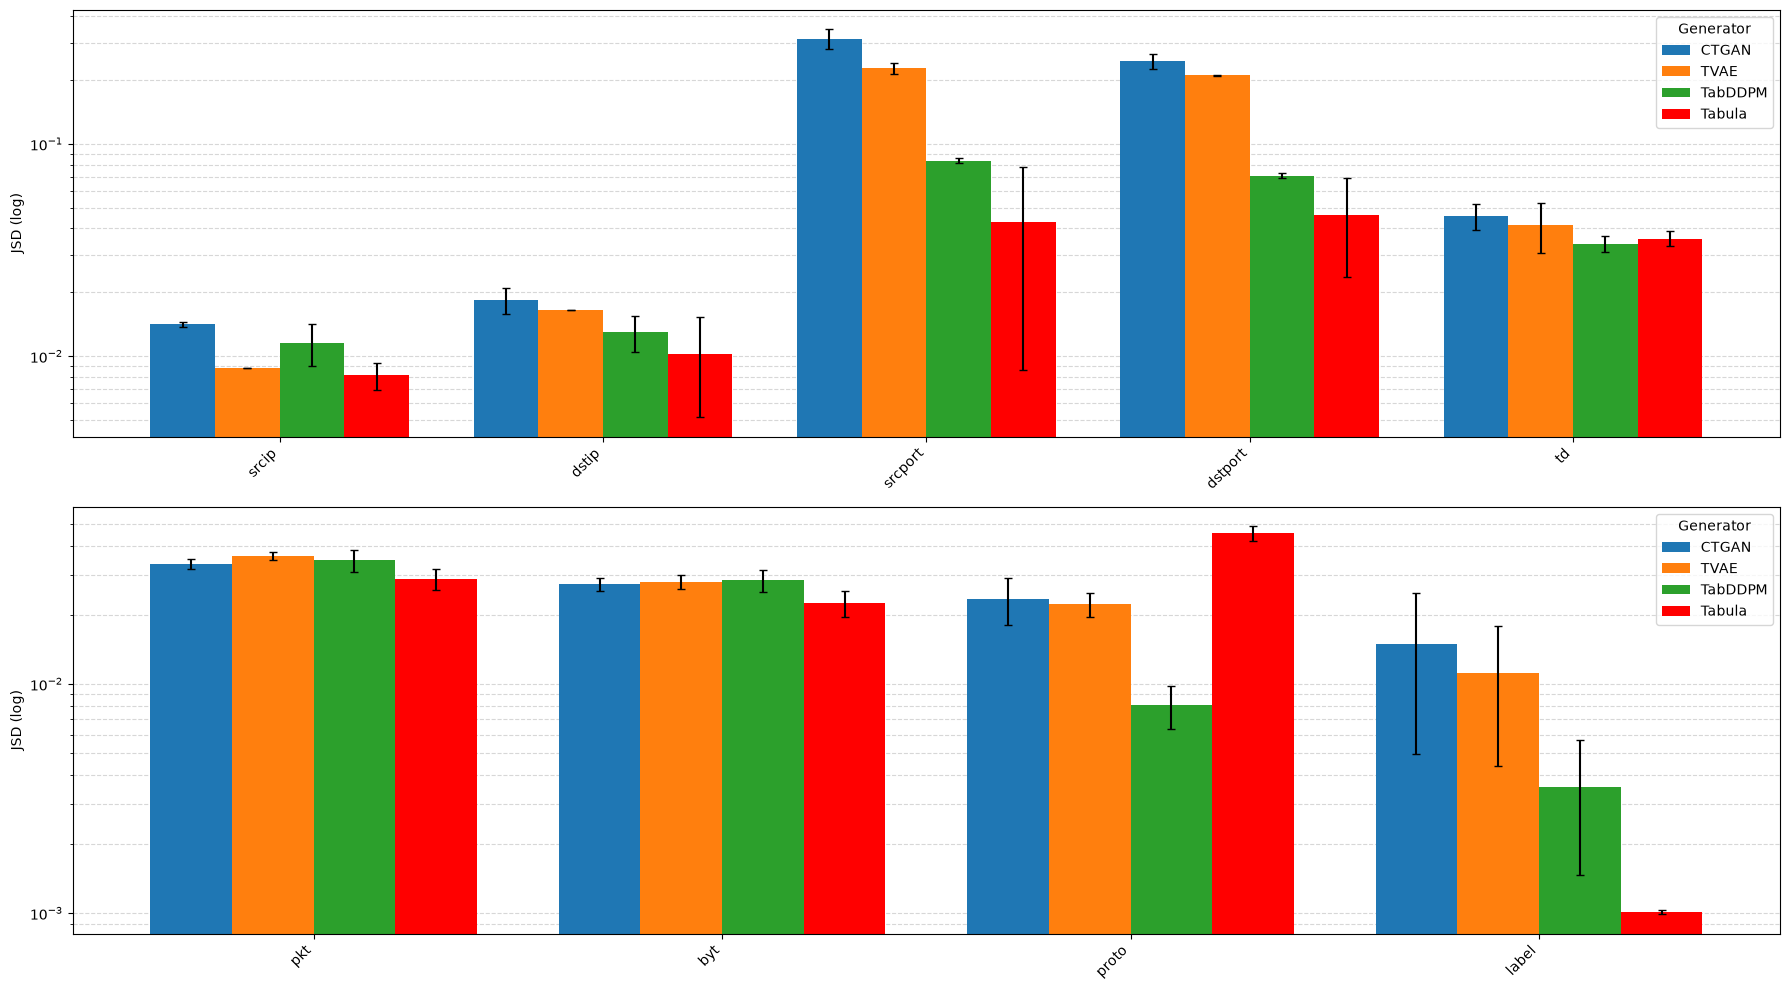

In [18]:
uipy.plot_fidelity_per_column(cidds_fidelity_expanded_df, 'JSD', cidds_col_names, cidds_name, n_parts=2, with_caption=False)

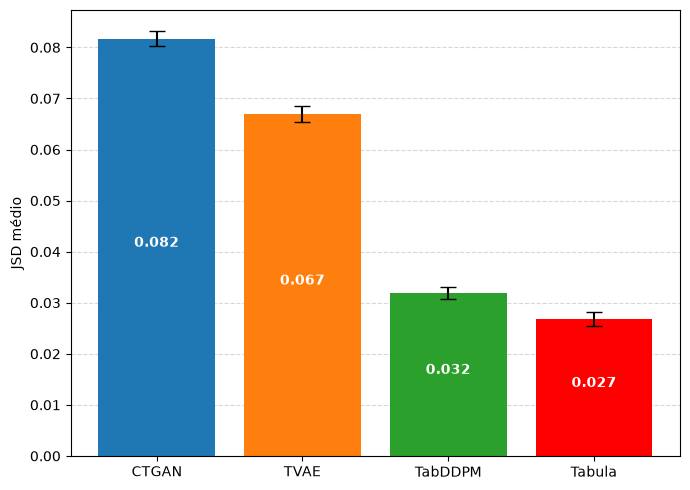

In [19]:
uipy.plot_fidelity_mean(cidds_fidelity_expanded_df, 'JSD', cidds_name, with_caption=False)

#### Fidelidade - Tabela

In [20]:
uipy.get_fidelity_table(cidds_fidelity_expanded_df)

,EMD,JSD
Gerador,,
CTGAN,0.270 ± 0.079,0.082 ± 0.001
TVAE,0.121 ± 0.018,0.067 ± 0.002
TabDDPM,0.054 ± 0.011,0.032 ± 0.001
Tabula,0.120 ± 0.048,0.027 ± 0.001


#### Utilidade - Gráficos

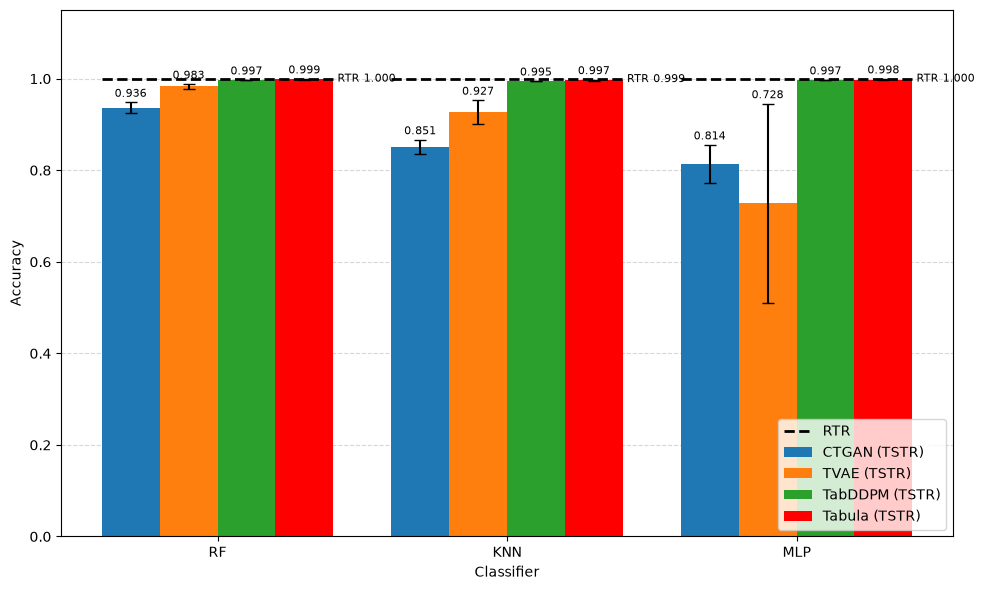

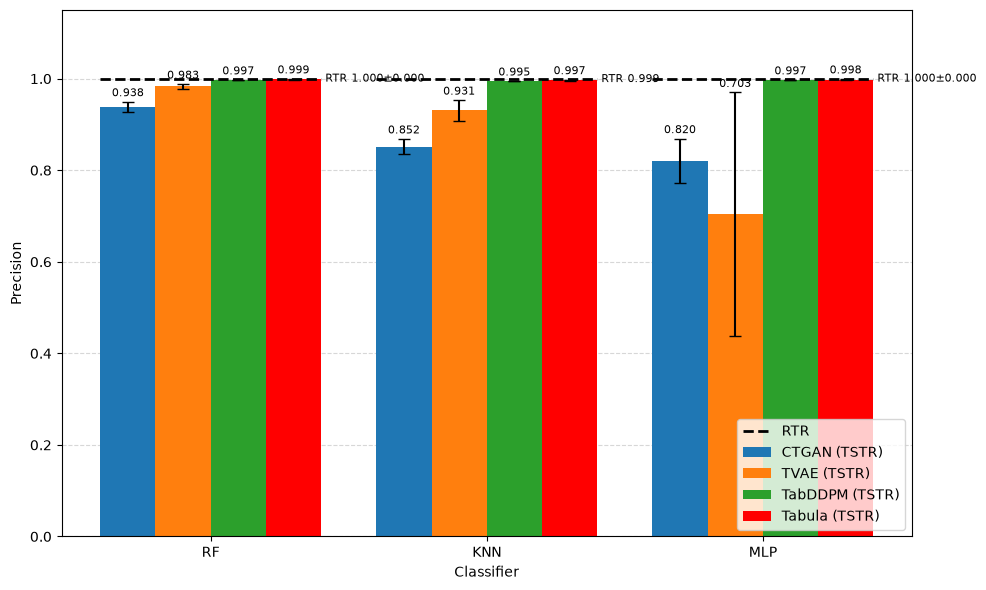

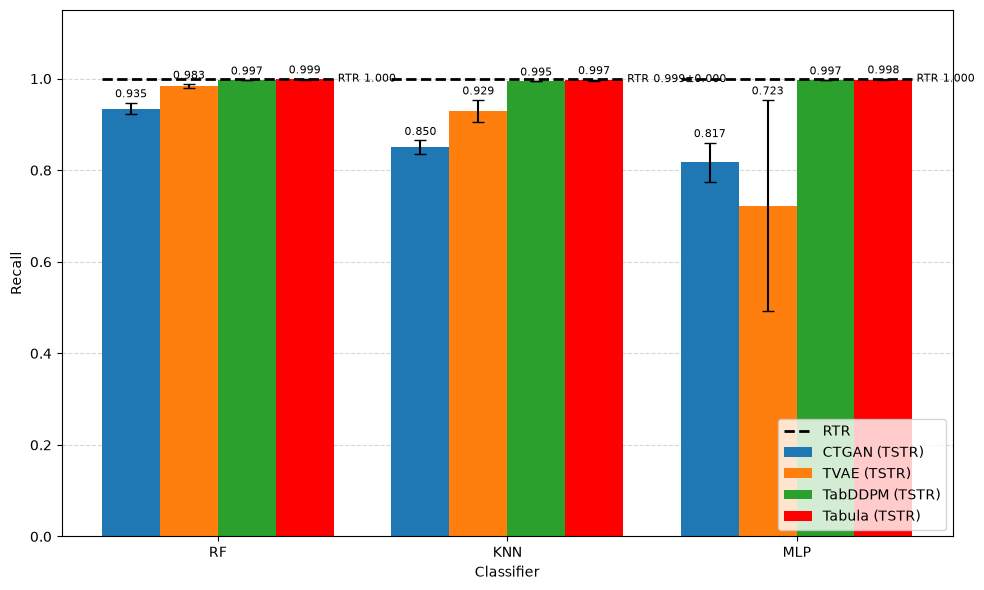

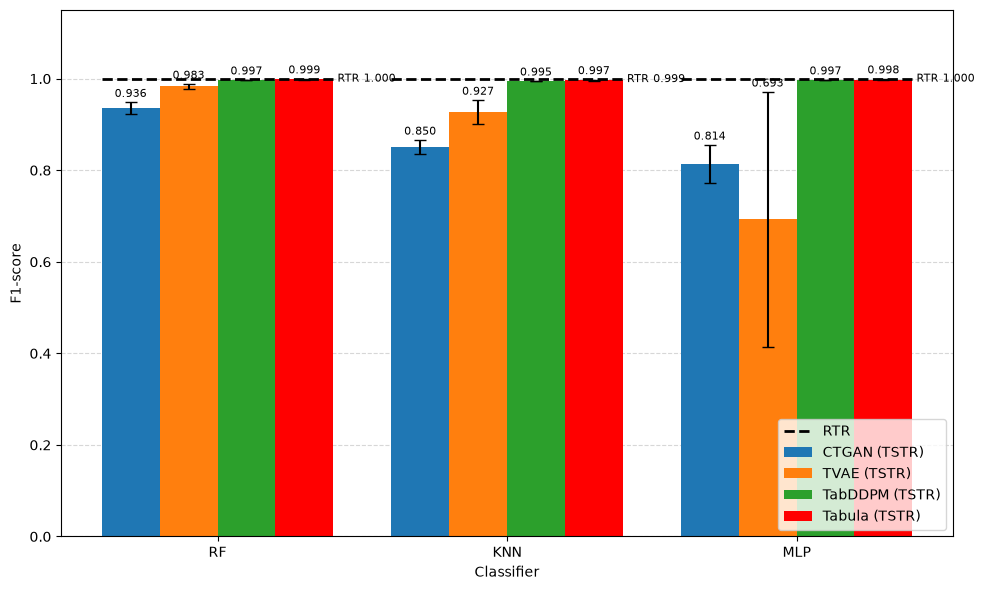

In [21]:
UTILITY_METRICS = ['accuracy', 'precision', 'recall', 'f1_score']

for metric in UTILITY_METRICS:
    uipy.plot_utility(cidds_utility_expanded_df, metric, cidds_name)


In [22]:
uipy.get_utility_table(cidds_utility_expanded_df, metric='f1_score')

,RF,KNN,MLP
Modelo,,,
Baseline (RTR),1.000 ± 0.000,0.999,1.000 ± 0.000
CTGAN,0.936 ± 0.012,0.850 ± 0.015,0.814 ± 0.041
TVAE,0.983 ± 0.005,0.927 ± 0.026,0.693 ± 0.278
TabDDPM,0.997 ± 0.000,0.995 ± 0.000,0.997 ± 0.000
Tabula,0.999 ± 0.001,0.997 ± 0.001,0.998 ± 0.002


#### Privacidade - Gráficos

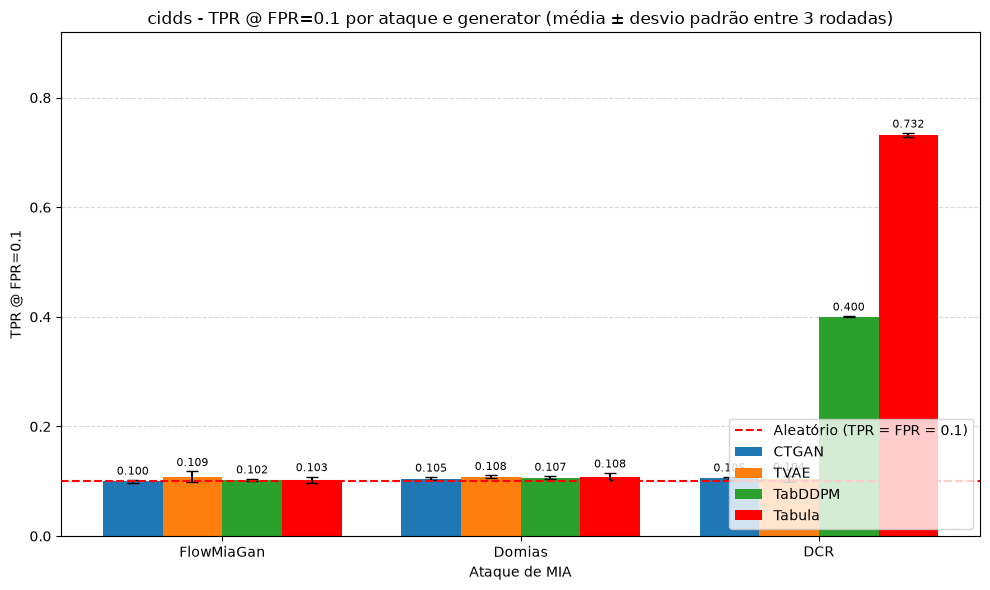

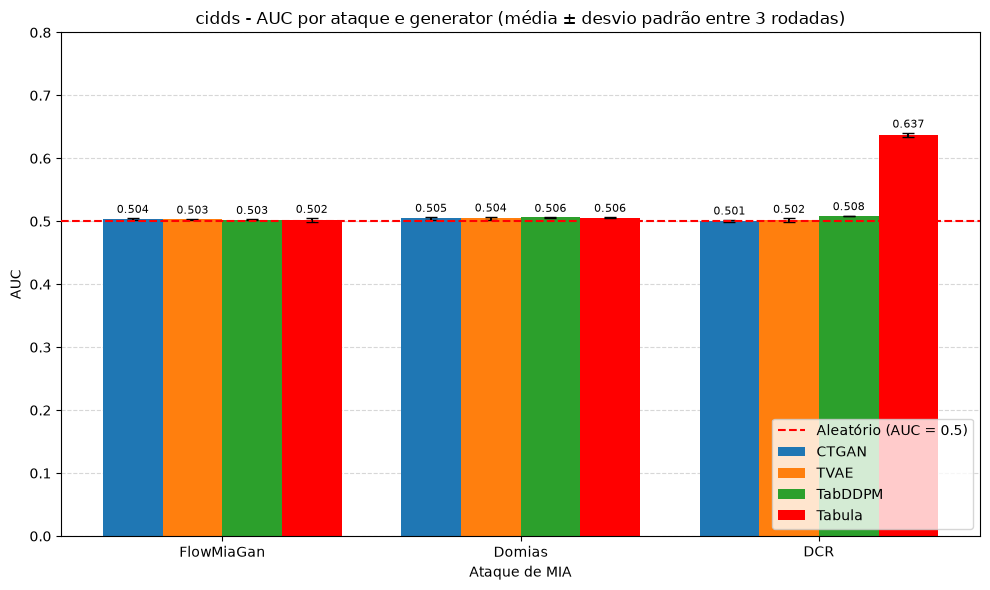

In [23]:
PRIVACY_METRICS = ['tpr@fpr', 'auc']

for metric in PRIVACY_METRICS:
    uipy.plot_privacy(cidds_privacy_expanded_df, metric, cidds_name)


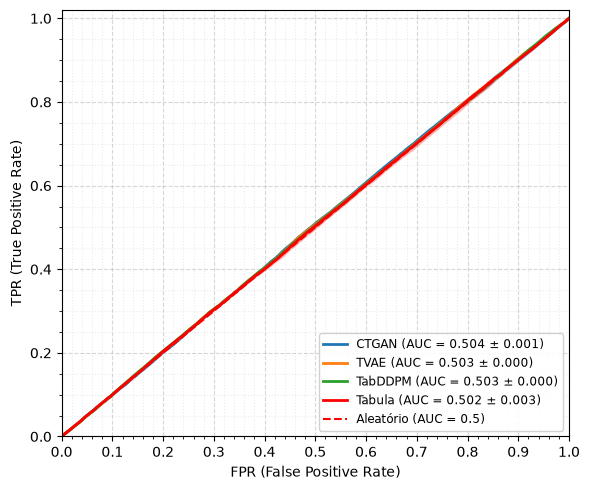

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [24]:
uipy.plot_mia_roc_curve(cidds_privacy_scores_expanded, cidds_name, attacks=['FlowMiaGan'], separate_plots=True)

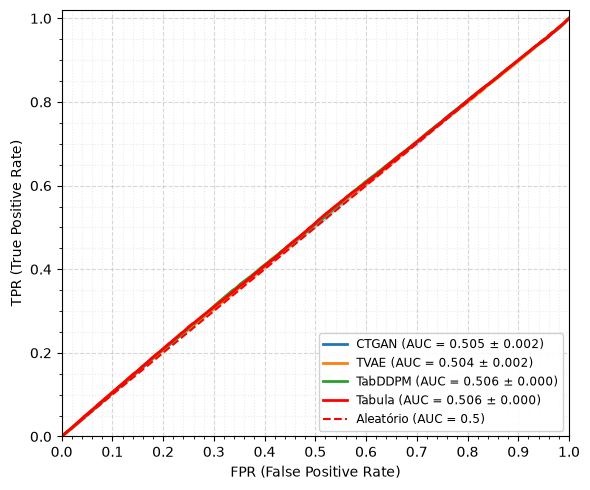

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [25]:
uipy.plot_mia_roc_curve(cidds_privacy_scores_expanded, cidds_name, attacks=['Domias'], separate_plots=True)

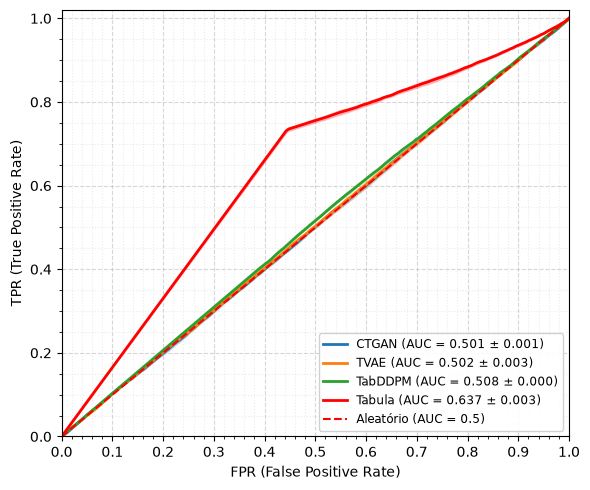

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [26]:
uipy.plot_mia_roc_curve(cidds_privacy_scores_expanded, cidds_name, attacks=['DCR'], separate_plots=True)

#### Privacidade - Tabela

In [27]:
uipy.get_privacy_table(cidds_privacy_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.504 ± 0.001  0.100 ± 0.002  0.505 ± 0.002  0.105 ± 0.003   
TVAE     0.503 ± 0.000  0.109 ± 0.009  0.504 ± 0.002  0.108 ± 0.003   
TabDDPM  0.503 ± 0.000  0.102 ± 0.002  0.506 ± 0.000  0.107 ± 0.003   
Tabula   0.502 ± 0.003  0.103 ± 0.006  0.506 ± 0.000  0.108 ± 0.007   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.501 ± 0.001  0.105 ± 0.003  
TVAE     0.502 ± 0.003  0.104 ± 0.005  
TabDDPM  0.508 ± 0.000  0.400 ± 0.001  
Tabula   0.637 ± 0.003  0.732 ± 0.003

### Default Credit

In [28]:
default_credit_name = 'default_credit'
default_credit_num, default_credit_cat, default_credit_label = uipy.get_dataset_columns_name(default_credit_name)
default_credit_col_names = default_credit_num + default_credit_cat + [default_credit_label]

default_credit_fidelity_df = uipy.get_all_fidelity_results('./results', default_credit_name, EXCLUDE_GENERATORS)
default_credit_fidelity_expanded_df = uipy.get_expanded_fidelity_df(default_credit_fidelity_df, default_credit_col_names)

default_credit_utility_df = uipy.get_all_utility_results('./results', default_credit_name, EXCLUDE_GENERATORS)
default_credit_utility_expanded_df = uipy.get_expanded_utility_df(default_credit_utility_df)

default_credit_privacy_df = uipy.get_all_privacy_results('./results', default_credit_name, EXCLUDE_GENERATORS)
default_credit_privacy_expanded_df = uipy.get_expanded_privacy_df(default_credit_privacy_df)

default_credit_privacy_scores = uipy.get_all_mia_scores_results('./results', default_credit_name, EXCLUDE_GENERATORS)
default_credit_privacy_scores_expanded = uipy.get_expanded_mia_scores_df(default_credit_privacy_scores)

#### Fidelidade - Gráficos

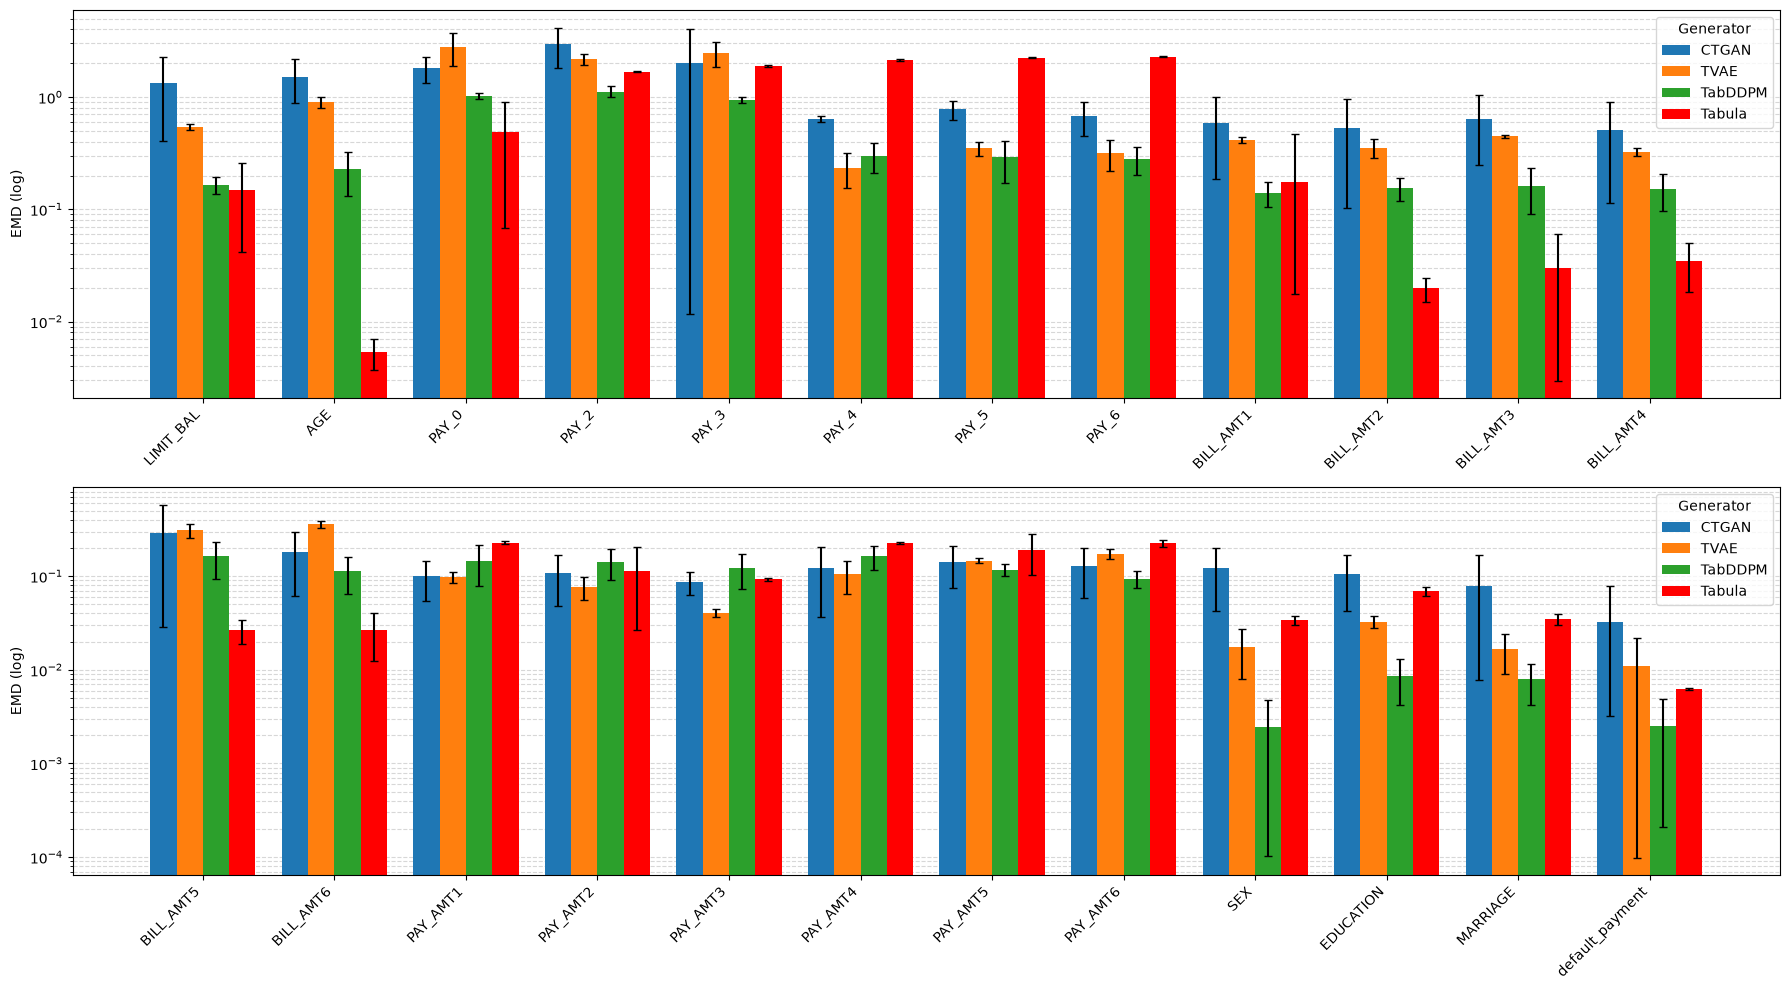

In [29]:
uipy.plot_fidelity_per_column(default_credit_fidelity_expanded_df, 'EMD', default_credit_col_names, default_credit_name, n_parts=2, with_caption=False)


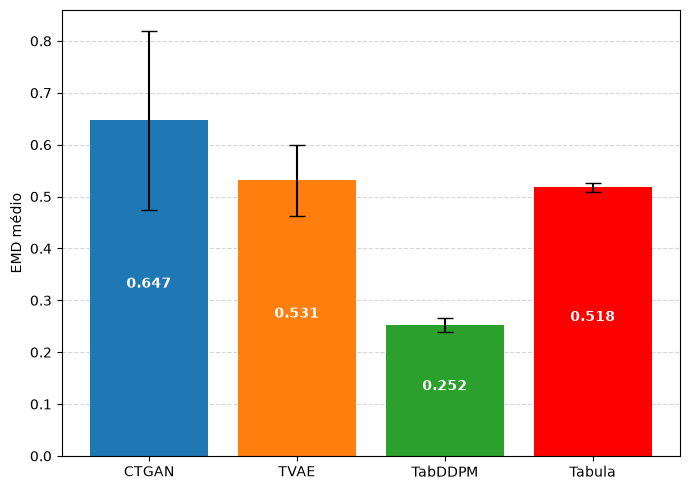

In [30]:
uipy.plot_fidelity_mean(default_credit_fidelity_expanded_df, 'EMD', default_credit_name, with_caption=False)

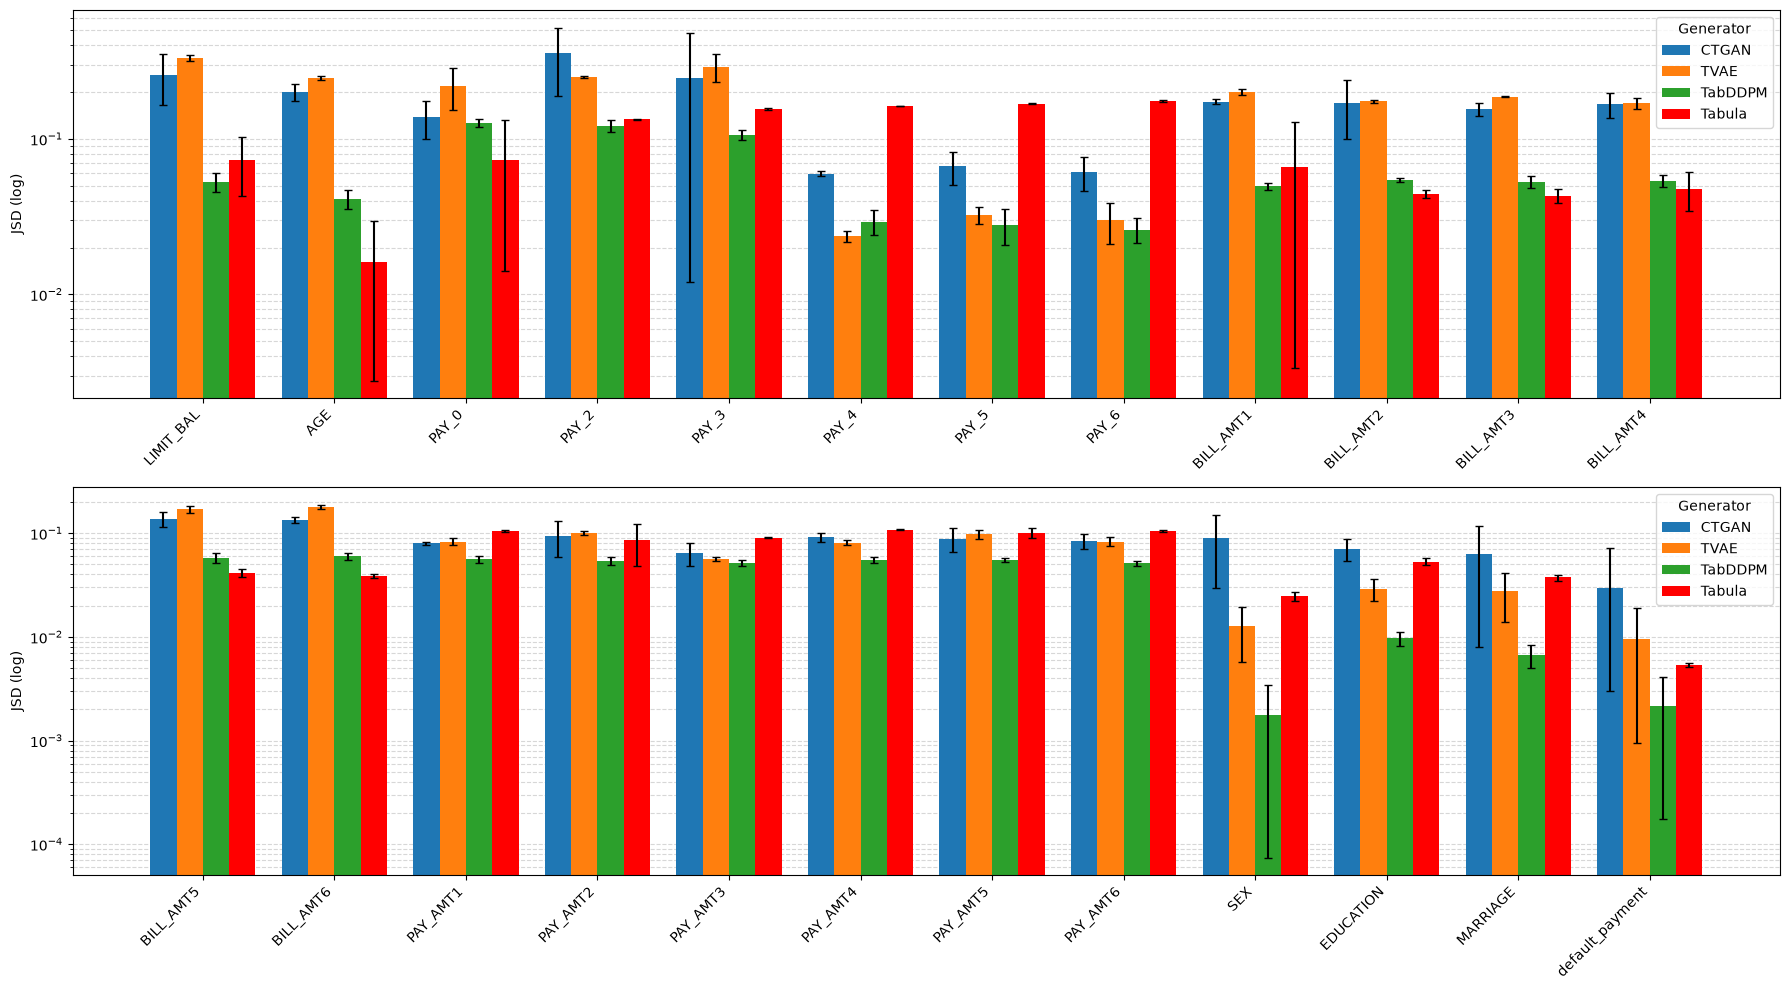

In [31]:
uipy.plot_fidelity_per_column(default_credit_fidelity_expanded_df, 'JSD', default_credit_col_names, default_credit_name, n_parts=2, with_caption=False)

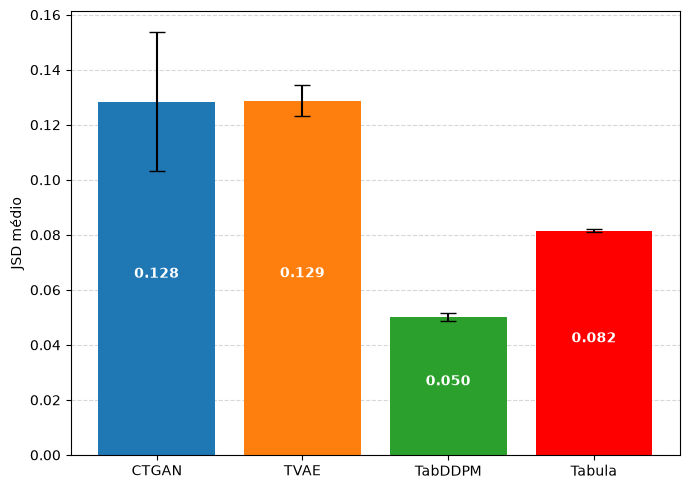

In [32]:
uipy.plot_fidelity_mean(default_credit_fidelity_expanded_df, 'JSD', default_credit_name, with_caption=False)

#### Fidelidade - Tabela

In [33]:
uipy.get_fidelity_table(default_credit_fidelity_expanded_df)

,EMD,JSD
Gerador,,
CTGAN,0.647 ± 0.172,0.128 ± 0.025
TVAE,0.531 ± 0.068,0.129 ± 0.005
TabDDPM,0.252 ± 0.013,0.050 ± 0.002
Tabula,0.518 ± 0.009,0.082 ± 0.001


#### Utilidade - Gráficos

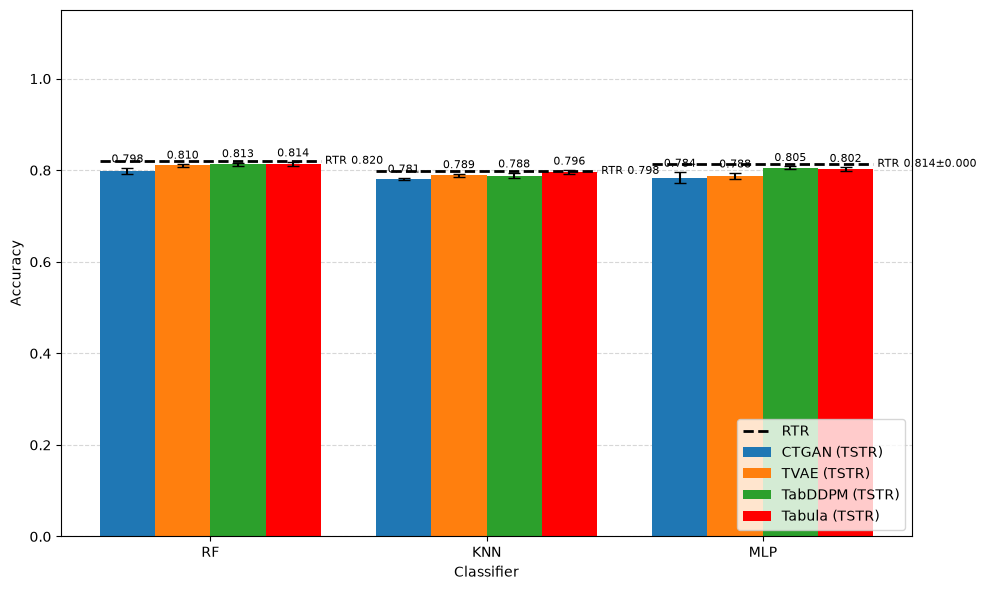

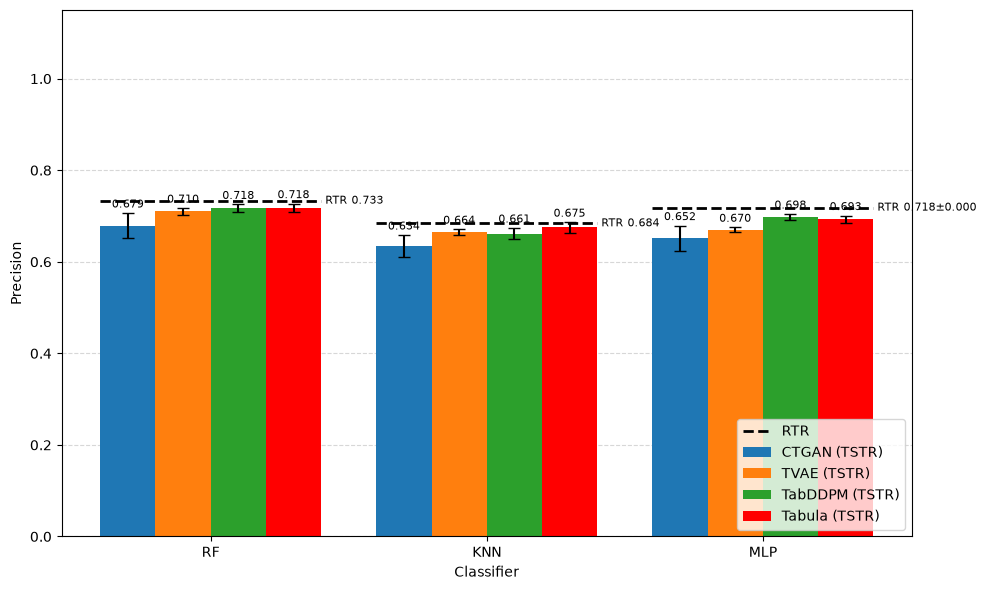

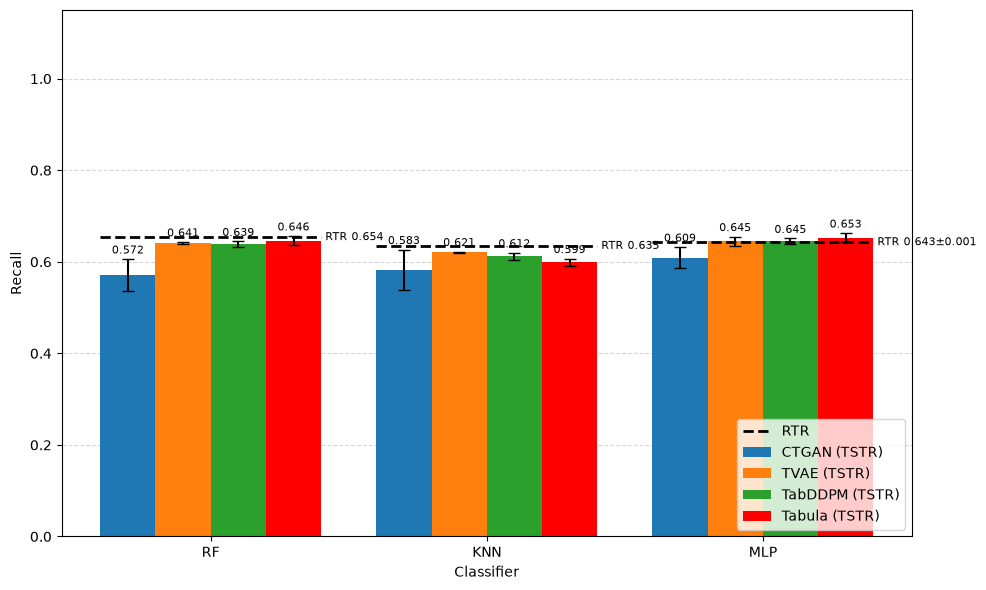

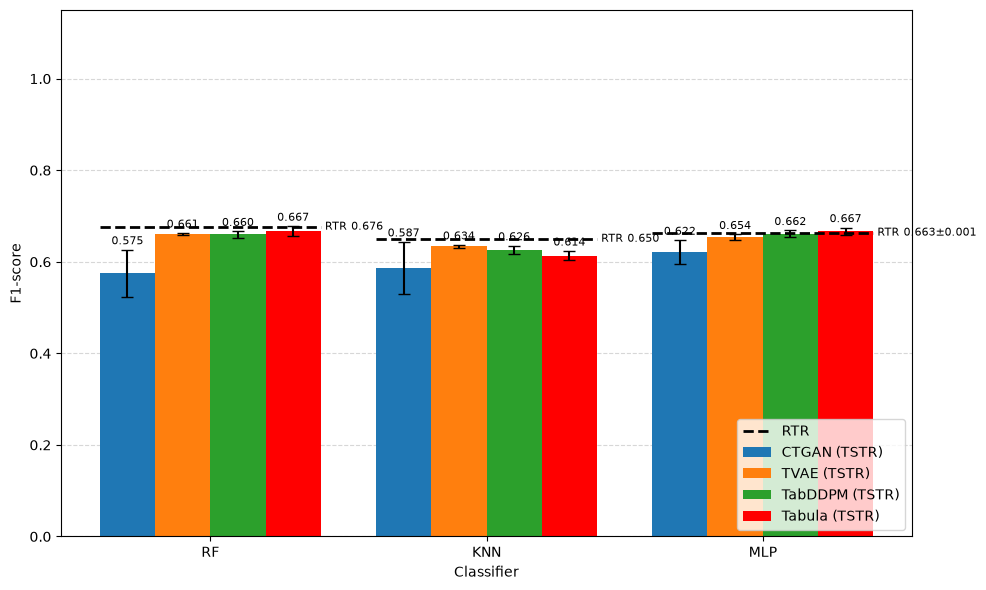

In [34]:
UTILITY_METRICS = ['accuracy', 'precision', 'recall', 'f1_score']

for metric in UTILITY_METRICS:
    uipy.plot_utility(default_credit_utility_expanded_df, metric, default_credit_name)


In [35]:
uipy.get_utility_table(default_credit_utility_expanded_df, metric='f1_score')

,RF,KNN,MLP
Modelo,,,
Baseline (RTR),0.676,0.650,0.663 ± 0.004
CTGAN,0.575 ± 0.051,0.587 ± 0.057,0.622 ± 0.026
TVAE,0.661 ± 0.002,0.634 ± 0.003,0.654 ± 0.006
TabDDPM,0.660 ± 0.007,0.626 ± 0.009,0.662 ± 0.007
Tabula,0.667 ± 0.011,0.614 ± 0.010,0.667 ± 0.008


#### Privacidade - Gráficos

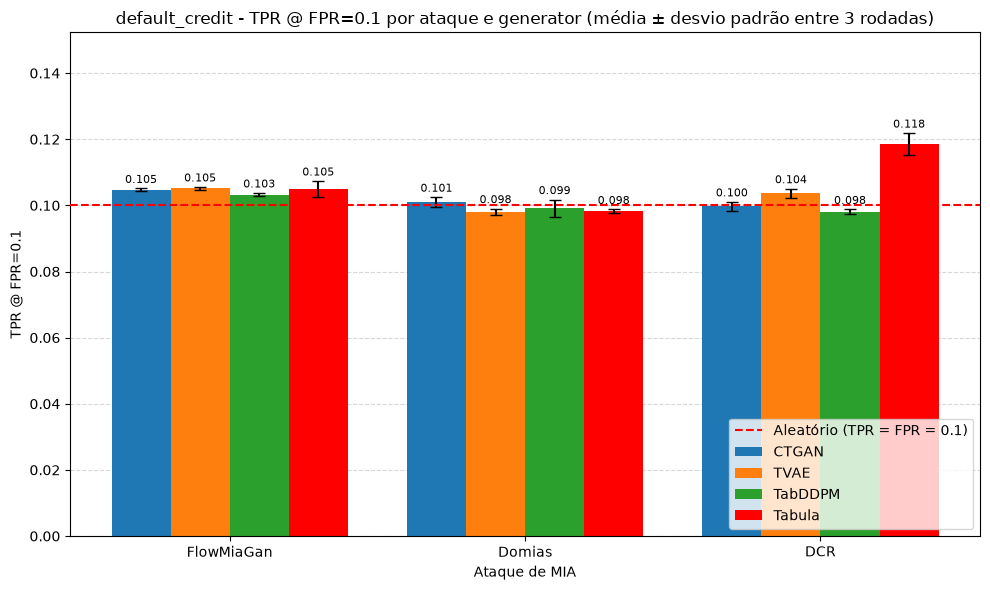

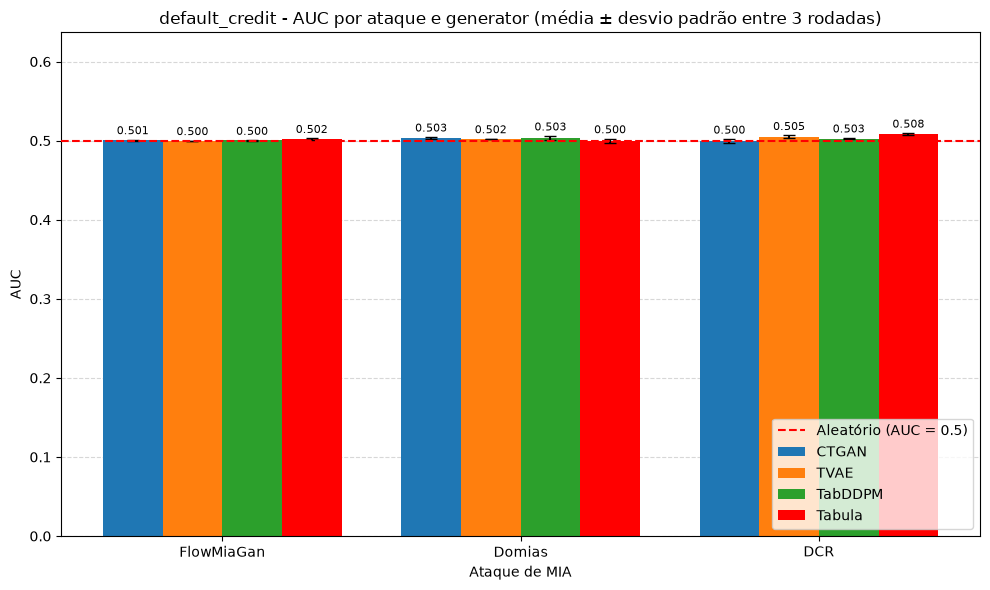

In [36]:
PRIVACY_METRICS = ['tpr@fpr', 'auc']

for metric in PRIVACY_METRICS:
    uipy.plot_privacy(default_credit_privacy_expanded_df, metric, default_credit_name)


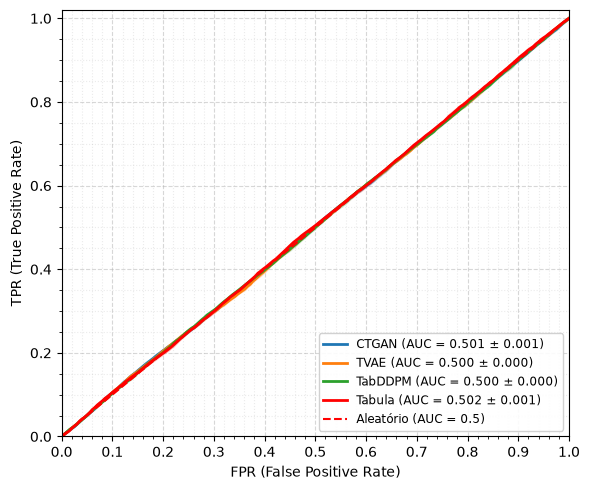

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [37]:
uipy.plot_mia_roc_curve(default_credit_privacy_scores_expanded, default_credit_name, attacks=['FlowMiaGan'], separate_plots=True)

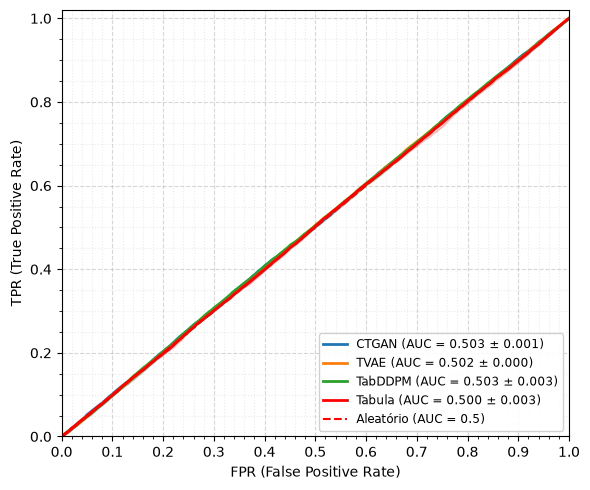

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [38]:
uipy.plot_mia_roc_curve(default_credit_privacy_scores_expanded, default_credit_name, attacks=['Domias'], separate_plots=True)

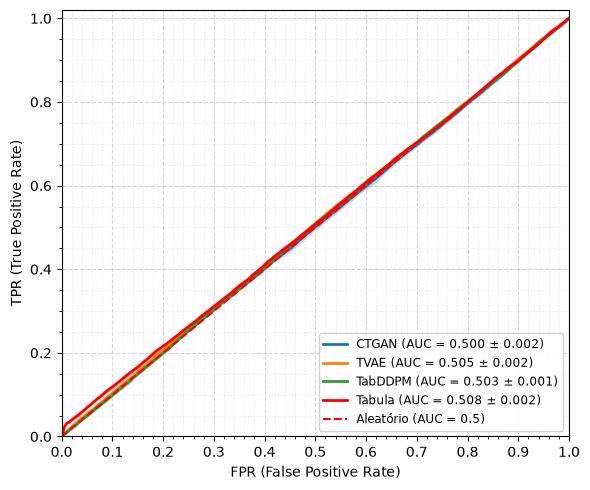

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [39]:
uipy.plot_mia_roc_curve(default_credit_privacy_scores_expanded, default_credit_name, attacks=['DCR'], separate_plots=True)

#### Privacidade - Tabela

In [40]:
uipy.get_privacy_table(default_credit_privacy_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.501 ± 0.001  0.105 ± 0.000  0.503 ± 0.001  0.101 ± 0.001   
TVAE     0.500 ± 0.000  0.105 ± 0.000  0.502 ± 0.000  0.098 ± 0.001   
TabDDPM  0.500 ± 0.000  0.103 ± 0.001  0.503 ± 0.003  0.099 ± 0.003   
Tabula   0.502 ± 0.001  0.105 ± 0.002  0.500 ± 0.003  0.098 ± 0.001   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.500 ± 0.002  0.100 ± 0.001  
TVAE     0.505 ± 0.002  0.104 ± 0.001  
TabDDPM  0.503 ± 0.001  0.098 ± 0.001  
Tabula   0.508 ± 0.002  0.118 ± 0.003